In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from pathlib import Path

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

from google.colab import files

uploaded = files.upload()
# Read the uploaded CSV file into a DataFrame
df = pd.read_csv(list(uploaded.keys())[0])
# Convert 'Order Date' to datetime objects
df['Order Date'] = pd.to_datetime(df['Order Date'])

# Ensure numeric fields are numeric.
for col in ["Sales", "Quantity", "Discount", "Profit"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["Month"] = df["Order Date"].dt.to_period("M").astype(str)

print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Date range:", df["Order Date"].min().date(), "to", df["Order Date"].max().date())
print("Missing values:", int(df.isna().sum().sum()))

Saving cleaned_superstore.csv to cleaned_superstore.csv
Rows: 9994
Columns: 22
Date range: 2014-01-03 to 2017-12-30
Missing values: 0


# Task 1:
The line chart is best for monthly sales because time is ordered and the line makes trends and turning points visible. The pie chart is weakest because it destroys the temporal sequence and makes month-to-month comparisons difficult.


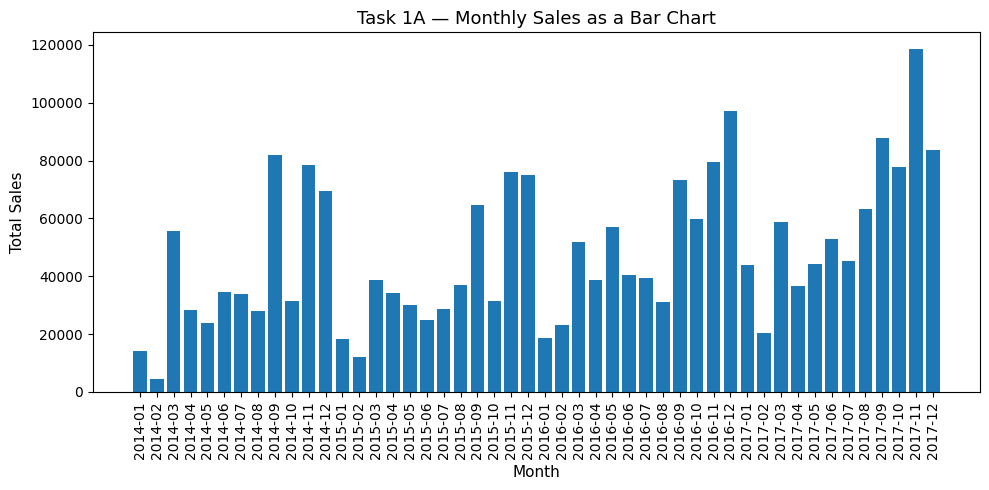

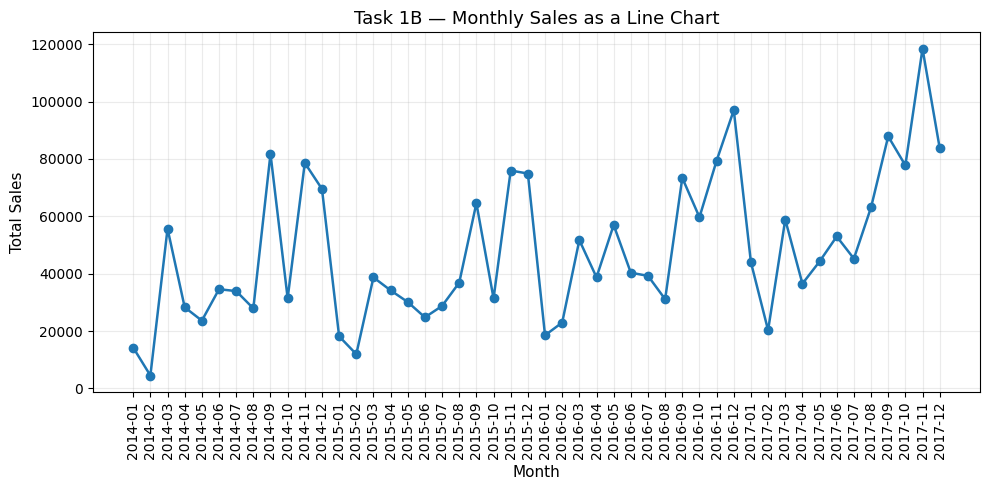

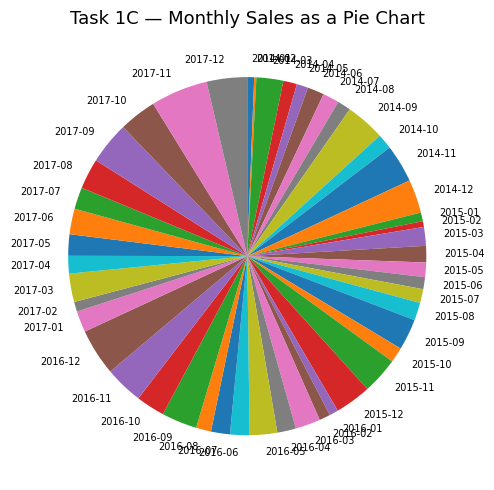

In [ ]:
monthly_sales = df.groupby("Month", sort=True)["Sales"].sum()

fig, ax = plt.subplots()
ax.bar(monthly_sales.index, monthly_sales.values)
ax.set_title("Task 1A — Monthly Sales as a Bar Chart")
ax.set_xlabel("Month")
ax.set_ylabel("Total Sales")
ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots()
ax.plot(monthly_sales.index, monthly_sales.values, marker="o", linewidth=1.8)
ax.set_title("Task 1B — Monthly Sales as a Line Chart")
ax.set_xlabel("Month")
ax.set_ylabel("Total Sales")
ax.tick_params(axis="x", rotation=90)
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots()
ax.pie(monthly_sales.values, labels=monthly_sales.index, startangle=90,
       counterclock=False, textprops={"fontsize": 7})
ax.set_title("Task 1C — Monthly Sales as a Pie Chart")
plt.tight_layout()
plt.show()


## Task 2 — Effectiveness & appropriateness

| Analytical statement | Best chart | Weak choice | Why |
|---|---|---|---|
| Compare total sales across the top 5 sub-categories | **Bar chart** | Pie chart | Bars make magnitude differences easy to compare; pie slices make close values harder to compare precisely. |
| Show the revenue trend over time | **Line chart** | Pie chart | A line preserves chronological order and makes movement over time visible; a pie has no useful time axis. |
| Show the distribution of order-line sales values | **Histogram** | Bar chart of categories | A histogram shows the spread and concentration of a continuous numeric variable; categorical bars do not show the distribution properly. |
| Show the relationship between discount level and profit | **Scatter plot** | Line chart | A scatter plot displays the paired raw observations and possible association; connecting observations with a line implies an arbitrary sequence. |


Bars are used for category magnitude comparisons, a line for the time trend, a histogram for the distribution of raw sales values, and a scatter plot for the relationship between discount and profit. These choices match the analytical structures described in the lab manual.

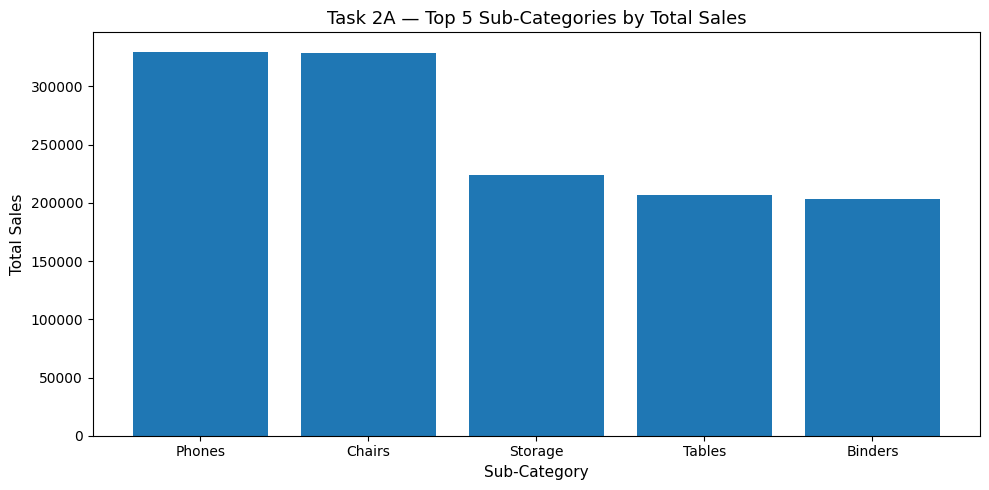

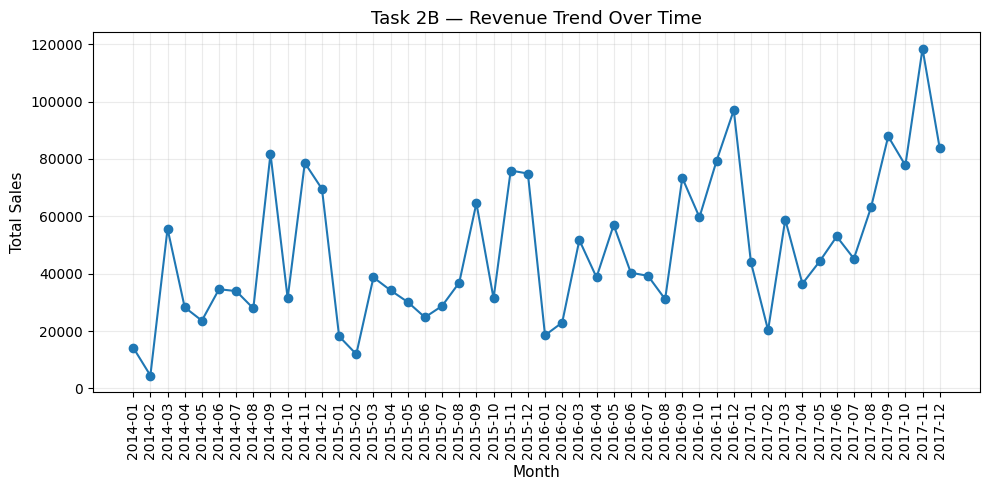

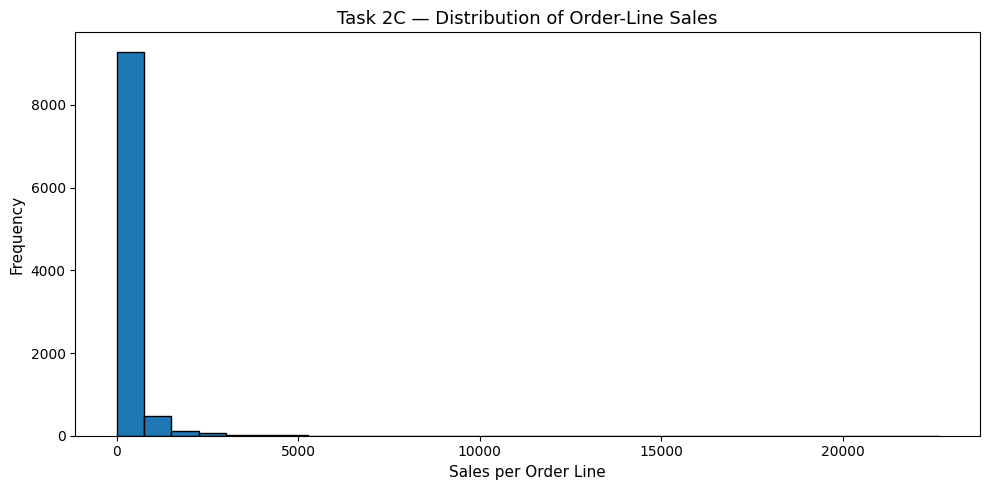

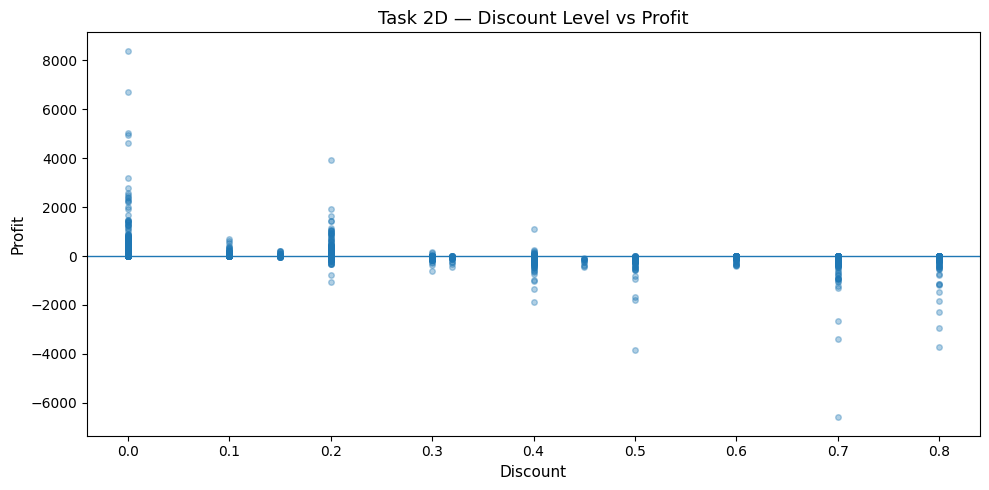

Top 5 sub-categories:
Sub-Category
Phones     330007.05
Chairs     328449.10
Storage    223843.61
Tables     206965.53
Binders    203412.73
Name: Sales, dtype: float64


In [ ]:
# 2A — Top 5 sub-categories by total sales
top5 = df.groupby("Sub-Category")["Sales"].sum().sort_values(ascending=False).head(5)

fig, ax = plt.subplots()
ax.bar(top5.index, top5.values)
ax.set_title("Task 2A — Top 5 Sub-Categories by Total Sales")
ax.set_xlabel("Sub-Category")
ax.set_ylabel("Total Sales")
plt.tight_layout()
plt.show()

# 2B — Revenue trend over time (reuse Task 1 monthly data)
fig, ax = plt.subplots()
ax.plot(monthly_sales.index, monthly_sales.values, marker="o")
ax.set_title("Task 2B — Revenue Trend Over Time")
ax.set_xlabel("Month")
ax.set_ylabel("Total Sales")
ax.tick_params(axis="x", rotation=90)
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

# 2C — Distribution of raw order-line sales
fig, ax = plt.subplots()
ax.hist(df["Sales"].dropna(), bins=30, edgecolor="black")
ax.set_title("Task 2C — Distribution of Order-Line Sales")
ax.set_xlabel("Sales per Order Line")
ax.set_ylabel("Frequency")
plt.tight_layout()
plt.show()

# 2D — Raw discount vs profit
fig, ax = plt.subplots()
ax.scatter(df["Discount"], df["Profit"], alpha=0.35, s=16)
ax.axhline(0, linewidth=1)
ax.set_title("Task 2D — Discount Level vs Profit")
ax.set_xlabel("Discount")
ax.set_ylabel("Profit")
plt.tight_layout()
plt.show()

print("Top 5 sub-categories:")
print(top5.round(2))


## Task 3 — Color selection

- **3(a) Region sales:** categorical data, use distinguishable categorical hues.
- **3(b) Region × category sales:** magnitude runs low to high, use a **sequential** palette.
- **3(c) Monthly profit:** values cross zero,  use a **diverging** palette centered on zero.

The palette choices : categorical for unordered groups, sequential for low→high magnitude, and diverging for values above/below a meaningful midpoint.


Regions use a categorical palette because regions are distinct groups. The region-by-category heatmap uses a sequential palette because darker/lighter intensity represents sales magnitude. Monthly profit uses a diverging palette because profit crosses zero.

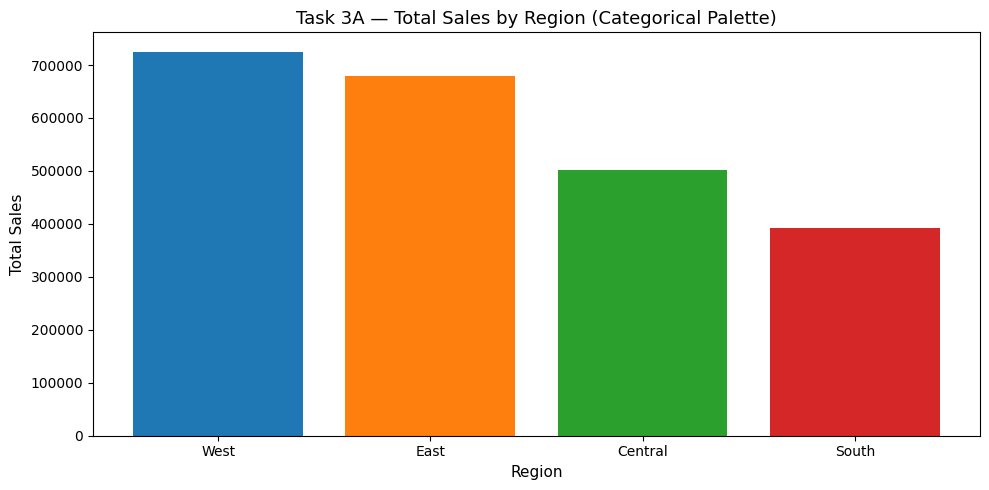

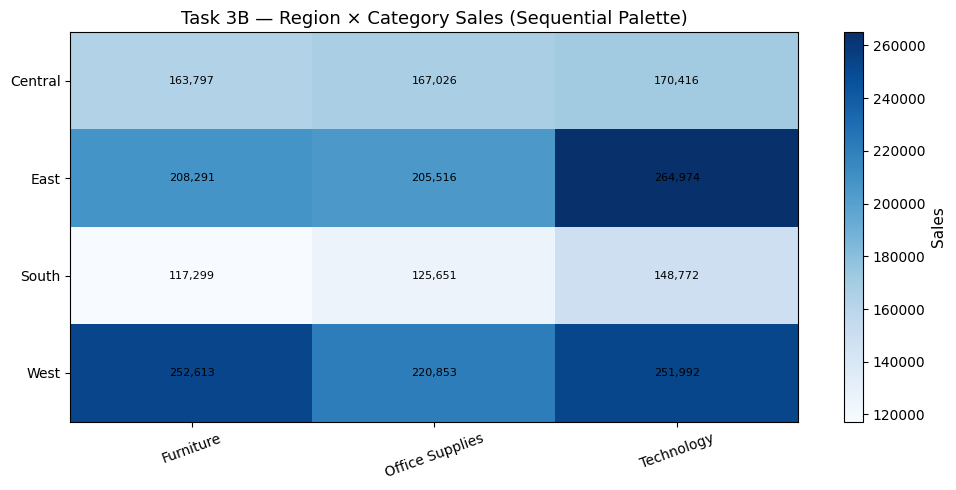

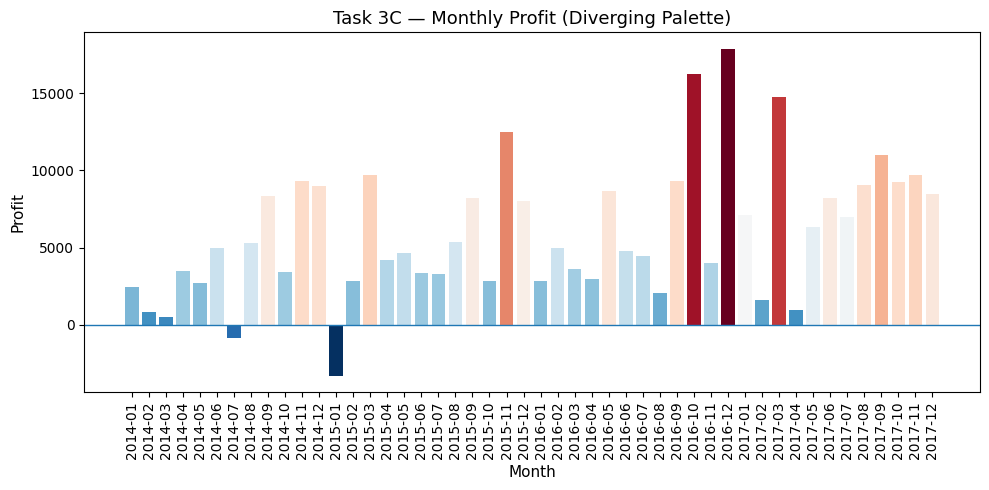

In [ ]:
region_sales = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)
region_category = df.pivot_table(index="Region", columns="Category",
                                 values="Sales", aggfunc="sum", fill_value=0)
monthly_profit = df.groupby("Month")["Profit"].sum()

# 3A — Proper categorical palette
fig, ax = plt.subplots()
ax.bar(region_sales.index, region_sales.values,
       color=plt.cm.tab10(np.arange(len(region_sales))))
ax.set_title("Task 3A — Total Sales by Region (Categorical Palette)")
ax.set_xlabel("Region")
ax.set_ylabel("Total Sales")
plt.tight_layout()
plt.show()

# 3B — Sequential heatmap
fig, ax = plt.subplots()
im = ax.imshow(region_category.values, cmap="Blues", aspect="auto")
ax.set_title("Task 3B — Region × Category Sales (Sequential Palette)")
ax.set_xticks(range(len(region_category.columns)), region_category.columns, rotation=20)
ax.set_yticks(range(len(region_category.index)), region_category.index)
for i in range(region_category.shape[0]):
    for j in range(region_category.shape[1]):
        ax.text(j, i, f"{region_category.iloc[i,j]:,.0f}",
                ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="Sales")
plt.tight_layout()
plt.show()

# 3C — Diverging monthly profit chart centered at zero
fig, ax = plt.subplots()
norm = plt.Normalize(monthly_profit.min(), monthly_profit.max())
bars = ax.bar(monthly_profit.index, monthly_profit.values,
              color=plt.cm.RdBu_r(norm(monthly_profit.values)))
ax.axhline(0, linewidth=1)
ax.set_title("Task 3C — Monthly Profit (Diverging Palette)")
ax.set_xlabel("Month")
ax.set_ylabel("Profit")
ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()


## Task 4 — WCAG contrast and color-blind accessibility

The WCAG function flags colors whose contrast against white is below 4.5:1. The red/green profit chart is deliberately problematic because color alone carries the meaning. Hatching fixes the issue by adding a non-color encoding.


In [ ]:
def wcag_contrast_ratio(rgb1, rgb2):
    """Return WCAG contrast ratio for two RGB colors in 0–255 format."""
    def relative_luminance(rgb):
        rgb = np.asarray(rgb, dtype=float) / 255.0
        linear = np.where(
            rgb <= 0.03928,
            rgb / 12.92,
            ((rgb + 0.055) / 1.055) ** 2.4
        )
        return 0.2126 * linear[0] + 0.7152 * linear[1] + 0.0722 * linear[2]

    l1 = relative_luminance(rgb1)
    l2 = relative_luminance(rgb2)
    hi, lo = max(l1, l2), min(l1, l2)
    return (hi + 0.05) / (lo + 0.05)

# Example colors used in Task 3 / Task 4.
tested_colors = {
    "blue": (31, 119, 180),
    "red": (214, 39, 40),
    "green": (44, 160, 44),
    "black": (0, 0, 0),
    "light_gray": (240, 240, 240),
}

print("Contrast against white background:")
for name, rgb in tested_colors.items():
    ratio = wcag_contrast_ratio(rgb, (255, 255, 255))
    status = "PASS" if ratio >= 4.5 else "FAIL"
    print(f"{name:10s} {ratio:.2f}:1  {status}")


Contrast against white background:
blue       4.82:1  PASS
red        5.02:1  PASS
green      3.40:1  FAIL
black      21.00:1  PASS
light_gray 1.14:1  FAIL


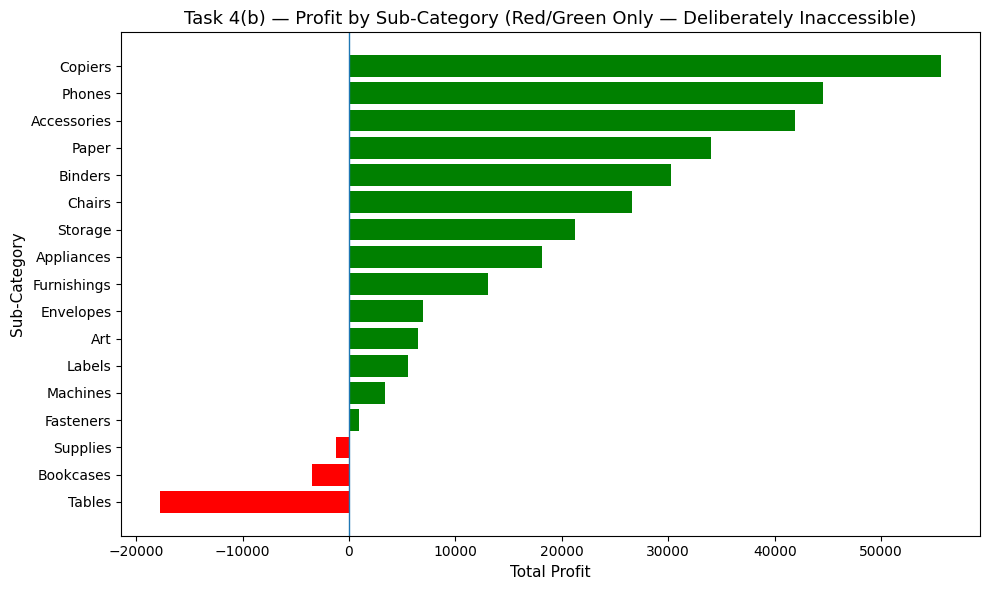

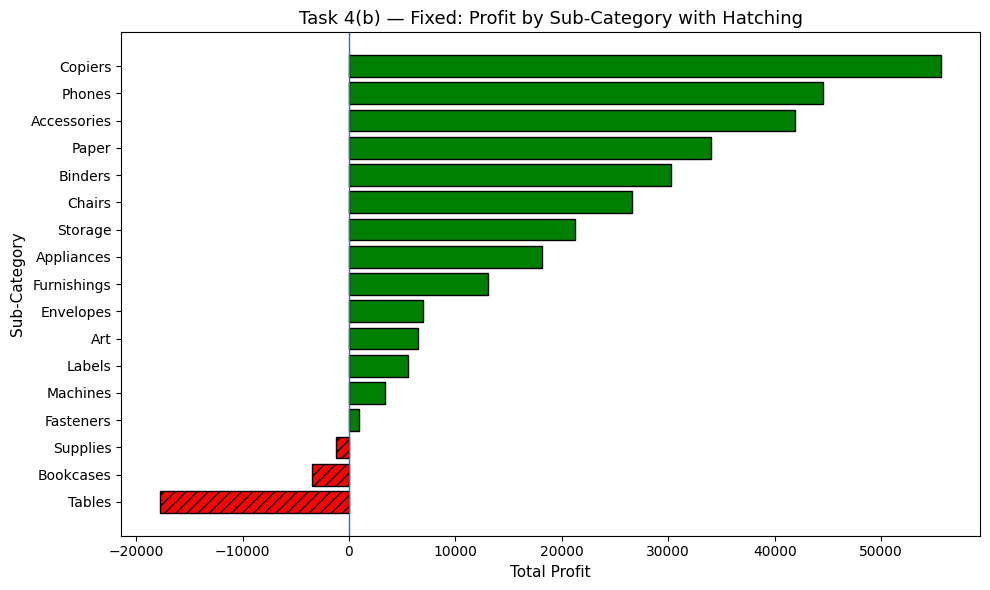

Alt text: Horizontal bars show total profit by sub-category; profitable categories extend right, the loss category extends left and is additionally marked with diagonal hatching.


In [ ]:
# Task 4(b) — Profit by sub-category: red/green-only version
subcategory_profit = df.groupby("Sub-Category")["Profit"].sum().sort_values()

red_green_colors = ["red" if x < 0 else "green" for x in subcategory_profit.values]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(subcategory_profit.index, subcategory_profit.values, color=red_green_colors)
ax.axvline(0, linewidth=1)
ax.set_title("Task 4(b) — Profit by Sub-Category (Red/Green Only — Deliberately Inaccessible)")
ax.set_xlabel("Total Profit")
ax.set_ylabel("Sub-Category")
plt.tight_layout()
plt.show()

# Fixed version: same red/green encoding, plus hatching for losses.
fig, ax = plt.subplots(figsize=(10, 6))
for i, (name, value) in enumerate(subcategory_profit.items()):
    is_loss = value < 0
    ax.barh(i, value,
            color="red" if is_loss else "green",
            hatch="///" if is_loss else "",
            edgecolor="black")
ax.axvline(0, linewidth=1)
ax.set_yticks(range(len(subcategory_profit)), subcategory_profit.index)
ax.set_title("Task 4(b) — Fixed: Profit by Sub-Category with Hatching")
ax.set_xlabel("Total Profit")
ax.set_ylabel("Sub-Category")
plt.tight_layout()
plt.show()

print("Alt text: Horizontal bars show total profit by sub-category; profitable categories extend right, the loss category extends left and is additionally marked with diagonal hatching.")


### Color-blind simulation note

The red/green chart above is the **before** version, and the hatched chart is the **after/fixed** version. The important design fix is independent of the exact simulator: **hatching supplies a non-color visual cue**, so loss vs. gain remains distinguishable even when red and green are difficult to separate.


## Task 5 — Deliberately misleading visualizations
The examples demonstrate truncated axes, dual axes, cherry-picked time windows, inverted axes, and radius-scaled bubbles. Each changes perception without changing the underlying data.

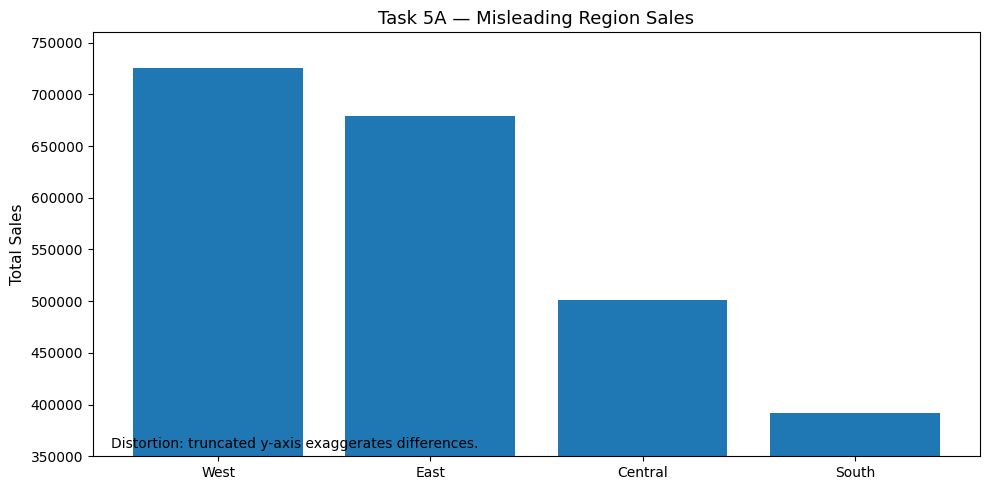

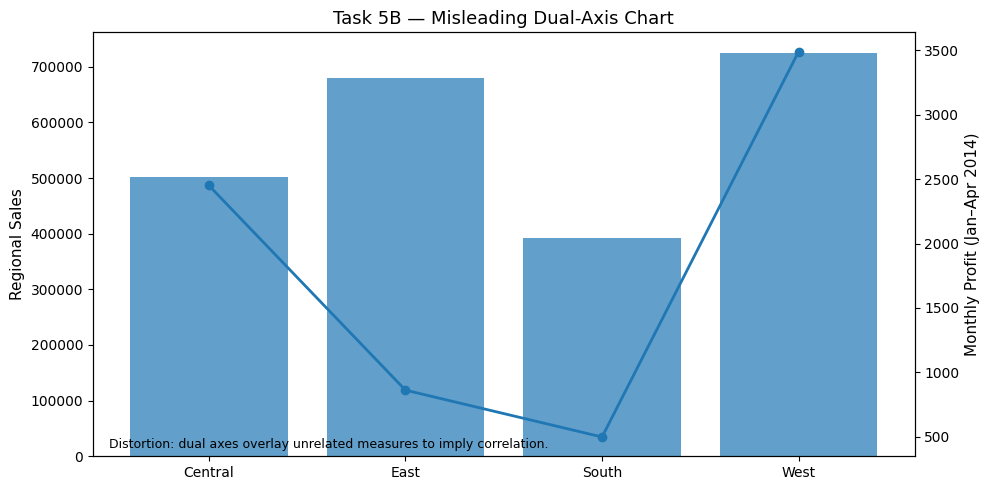

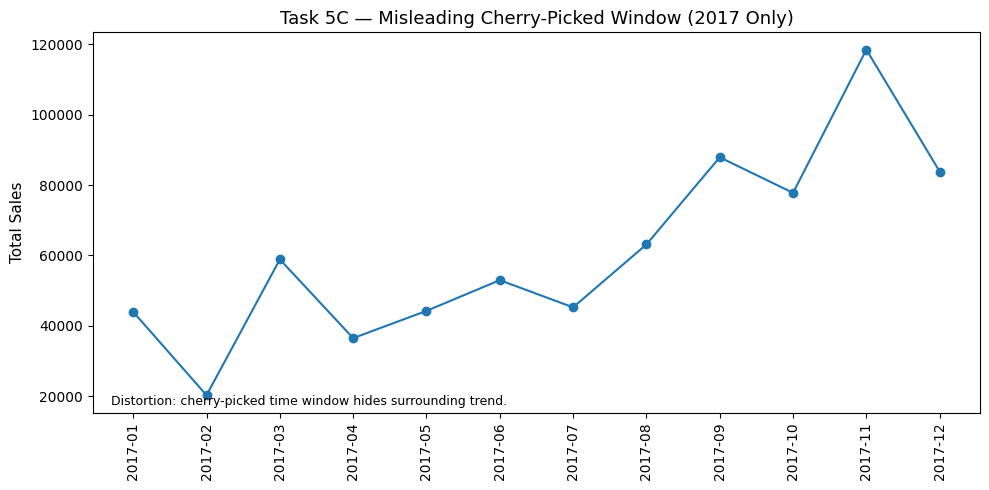

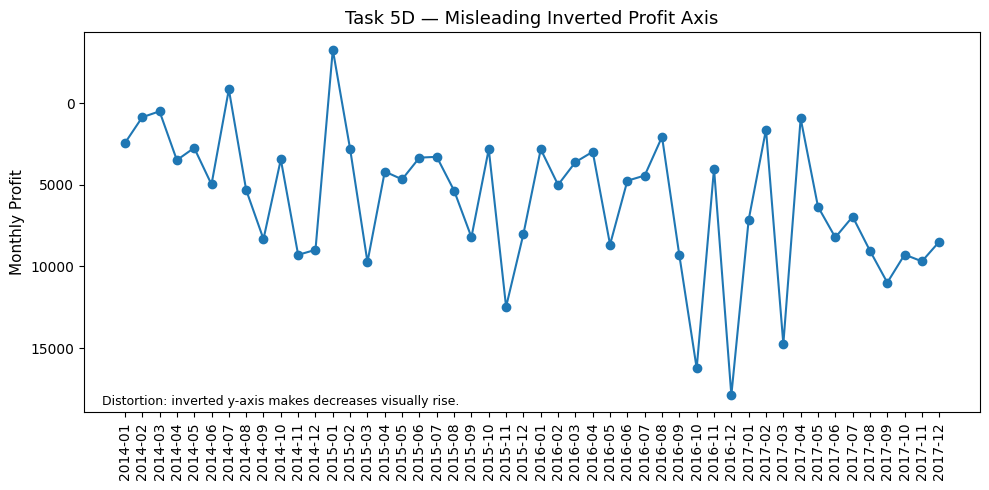

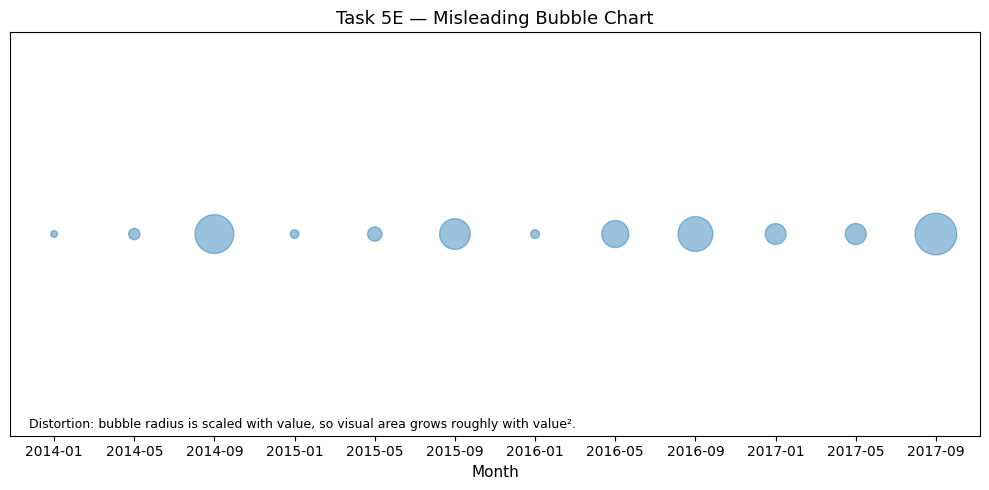

In [ ]:
region_sales = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)
monthly_profit = df.groupby("Month")["Profit"].sum()

# 5A — Truncated y-axis on region sales
fig, ax = plt.subplots()
ax.bar(region_sales.index, region_sales.values)
ax.set_ylim(350000, 760000)  # deliberately truncates the y-axis
ax.set_title("Task 5A — Misleading Region Sales")
ax.set_ylabel("Total Sales")
ax.text(0.02, 0.02, "Distortion: truncated y-axis exaggerates differences.",
        transform=ax.transAxes, fontsize=10)
plt.tight_layout()
plt.show()

# 5B — Dual axes using unrelated measures
# First four regions are placed beside the first four months only to create a false visual pairing.
profit_first4 = monthly_profit.iloc[:4]
fig, ax1 = plt.subplots()
x = np.arange(4)
ax1.bar(x, region_sales.loc[["Central","East","South","West"]].values, alpha=0.7)
ax1.set_ylabel("Regional Sales")
ax1.set_xticks(x, ["Central","East","South","West"])
ax2 = ax1.twinx()
ax2.plot(x, profit_first4.values, marker="o", linewidth=2)
ax2.set_ylabel("Monthly Profit (Jan–Apr 2014)")
ax1.set_title("Task 5B — Misleading Dual-Axis Chart")
ax1.text(0.02, 0.02, "Distortion: dual axes overlay unrelated measures to imply correlation.",
         transform=ax1.transAxes, fontsize=9)
plt.tight_layout()
plt.show()

# 5C — Cherry-picked date window
all_years = monthly_sales
cherry = monthly_sales[monthly_sales.index.str.startswith("2017")]

fig, ax = plt.subplots()
ax.plot(cherry.index, cherry.values, marker="o")
ax.set_title("Task 5C — Misleading Cherry-Picked Window (2017 Only)")
ax.set_ylabel("Total Sales")
ax.tick_params(axis="x", rotation=90)
ax.text(0.02, 0.02, "Distortion: cherry-picked time window hides surrounding trend.",
        transform=ax.transAxes, fontsize=9)
plt.tight_layout()
plt.show()

# 5D — Inverted y-axis
fig, ax = plt.subplots()
ax.plot(monthly_profit.index, monthly_profit.values, marker="o")
ax.invert_yaxis()
ax.set_title("Task 5D — Misleading Inverted Profit Axis")
ax.set_ylabel("Monthly Profit")
ax.tick_params(axis="x", rotation=90)
ax.text(0.02, 0.02, "Distortion: inverted y-axis makes decreases visually rise.",
        transform=ax.transAxes, fontsize=9)
plt.tight_layout()
plt.show()

# 5E — Bubble chart where radius, rather than area, is proportional to value.
# Matplotlib 's' is marker AREA, so using s proportional to value^2 makes radius proportional to value.
bubble = monthly_sales.iloc[::4]  # keep the plot readable
sizes = (bubble.values / bubble.values.max() * 900) ** 2 / 900

fig, ax = plt.subplots()
ax.scatter(bubble.index, np.zeros(len(bubble)), s=sizes, alpha=0.45)
ax.set_yticks([])
ax.set_title("Task 5E — Misleading Bubble Chart")
ax.set_xlabel("Month")
ax.text(0.02, 0.02, "Distortion: bubble radius is scaled with value, so visual area grows roughly with value².",
        transform=ax.transAxes, fontsize=9)
plt.tight_layout()
plt.show()

## Task 6 — One real analytical question

### Question: Is discounting hurting profit?

**Honest chart:** a scatter plot of the raw `Discount` and `Profit` columns. This is appropriate because the task asks for the relationship between two numeric variables without summarizing.

**Misleading version:** the same relationship is shown with an **inverted profit axis**, which reverses the visual direction and can make a negative association look visually positive.

**Color choice:** a single neutral hue is used for the honest scatter because the analytical question does not require categorical color coding.

**Accessibility check:** the chart does not rely on red vs. green; the axes and zero line provide textual/positional cues.


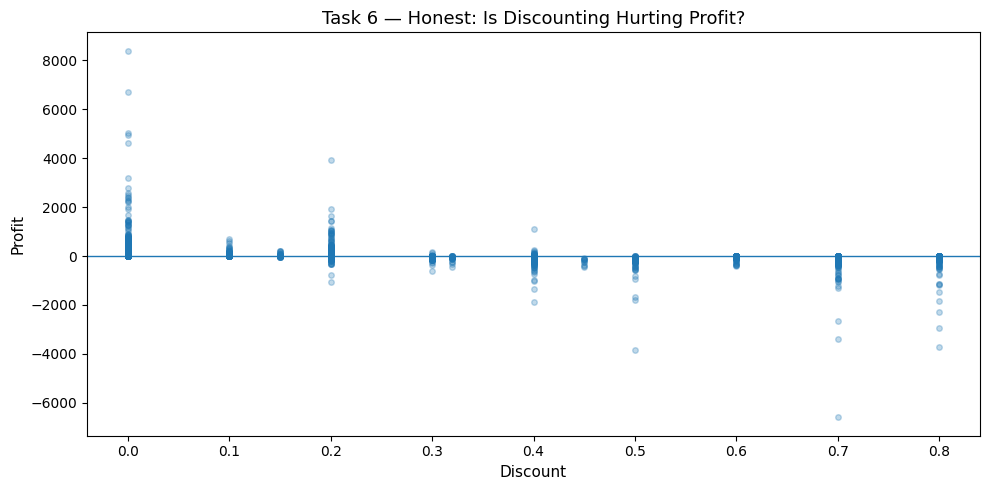

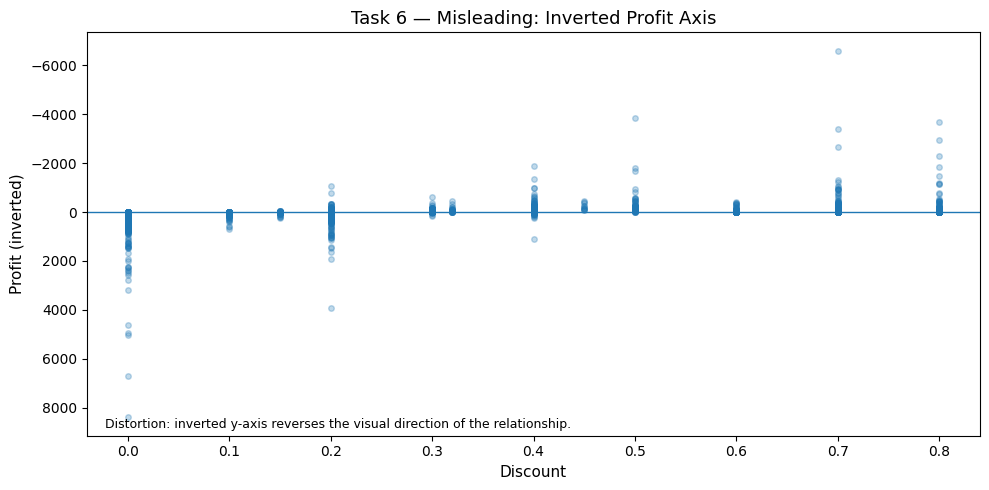

Pearson correlation between raw Discount and Profit: -0.219


In [ ]:
# Honest version
fig, ax = plt.subplots()
ax.scatter(df["Discount"], df["Profit"], alpha=0.28, s=16)
ax.axhline(0, linewidth=1)
ax.set_title("Task 6 — Honest: Is Discounting Hurting Profit?")
ax.set_xlabel("Discount")
ax.set_ylabel("Profit")
plt.tight_layout()
plt.show()

# Deliberately misleading version
fig, ax = plt.subplots()
ax.scatter(df["Discount"], df["Profit"], alpha=0.28, s=16)
ax.axhline(0, linewidth=1)
ax.invert_yaxis()
ax.set_title("Task 6 — Misleading: Inverted Profit Axis")
ax.set_xlabel("Discount")
ax.set_ylabel("Profit (inverted)")
ax.text(0.02, 0.02, "Distortion: inverted y-axis reverses the visual direction of the relationship.",
        transform=ax.transAxes, fontsize=9)
plt.tight_layout()
plt.show()

corr = df["Discount"].corr(df["Profit"])
print(f"Pearson correlation between raw Discount and Profit: {corr:.3f}")


The honest scatter plot directly represents the raw paired observations. The misleading version keeps the same observations but inverts the profit axis, demonstrating how an axis manipulation can change the visual story.